In [2]:
import os
import sys

os.environ["SPARK_HOME"] = "/opt/spark"

sys.path.insert(0, "/opt/spark/python")
sys.path.insert(0, "/opt/spark/python/lib/py4j-0.10.9.7-src.zip")

import pyspark

print("PySpark version:", pyspark.__version__)

PySpark version: 3.5.9


In [3]:
from pyspark.sql import SparkSession

os.environ["PYSPARK_PYTHON"] = "/usr/bin/python3"

spark = (
    SparkSession.builder
    .master("spark://spark-master:7077")
    .appName("US Accidents - Data Exploration")
    .config("spark.driver.host", "spark-master")
    .config("spark.driver.bindAddress", "0.0.0.0")
    .config("spark.executor.memory", "1g")
    .config("spark.cores.max", "2")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)

:: loading settings :: url = jar:file:/opt/spark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml


Ivy Default Cache set to: /tmp/spark-ivy/cache
The jars for the packages stored in: /tmp/spark-ivy/jars
org.postgresql#postgresql added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-366bef1d-5bbe-4e8a-9e5e-069cf97c0712;1.0
	confs: [default]
	found org.postgresql#postgresql;42.7.14 in central
	found org.checkerframework#checker-qual;3.55.1 in central
:: resolution report :: resolve 288ms :: artifacts dl 5ms
	:: modules in use:
	org.checkerframework#checker-qual;3.55.1 from central in [default]
	org.postgresql#postgresql;42.7.14 from central in [default]
	---------------------------------------------------------------------
	|                  |            modules            ||   artifacts   |
	|       conf       | number| search|dwnlded|evicted|| number|dwnlded|
	---------------------------------------------------------------------
	|      default     |   2   |   0   |   0   |   0   ||   2   |   0   |
	-------------------------------------------------

Spark version: 3.5.9
Spark master: spark://spark-master:7077



# Описание датасета US Accidents

Датасет содержит 7 728 394 записи о дорожно-транспортных происшествиях в США за 2016–2023 годы и 46 признаков.

## 1. Основная информация о ДТП

| Столбец | Описание |
|---|---|
| ID | Уникальный идентификатор ДТП |
| Source | Источник данных о происшествии |
| Severity | Степень влияния ДТП на дорожное движение: от 1 (минимальное) до 4 (максимальное) |
| Start_Time | Дата и время начала происшествия |
| End_Time | Дата и время окончания влияния ДТП на движение |
| Start_Lat | Географическая широта начальной точки |
| Start_Lng | Географическая долгота начальной точки |
| End_Lat | Широта конечной точки затронутого участка |
| End_Lng | Долгота конечной точки затронутого участка |
| Distance(mi) | Протяжённость затронутого участка дороги в милях |
| Description | Текстовое описание происшествия |
| Street | Название улицы |
| City | Город |
| County | Округ |
| State | Штат США |
| Zipcode | Почтовый индекс |
| Country | Страна |
| Timezone | Часовой пояс места происшествия |
| Airport_Code | Код ближайшей аэропортовой метеостанции |
| Weather_Timestamp | Дата и время метеорологического наблюдения |

## 2. Погодные условия

| Столбец | Описание |
|---|---|
| Temperature(F) | Температура воздуха в градусах Фаренгейта |
| Wind_Chill(F) | Ощущаемая температура с учётом ветра, °F |
| Humidity(%) | Относительная влажность воздуха, % |
| Pressure(in) | Атмосферное давление в дюймах ртутного столба |
| Visibility(mi) | Дальность видимости в милях |
| Wind_Direction | Направление ветра |
| Wind_Speed(mph) | Скорость ветра в милях в час |
| Precipitation(in) | Количество осадков в дюймах |
| Weather_Condition | Описание погоды: дождь, снег, туман, ясно и т. д. |

## 3. Дорожная инфраструктура

Булевы признаки (True/False), показывающие наличие соответствующего объекта поблизости от места ДТП.

| Столбец | Описание |
|---|---|
| Amenity | Наличие объекта инфраструктуры или общественного удобства |
| Bump | Наличие искусственной дорожной неровности |
| Crossing | Наличие пешеходного перехода |
| Give_Way | Наличие знака «Уступи дорогу» |
| Junction | Наличие перекрёстка или дорожного соединения |
| No_Exit | Наличие тупика или участка без сквозного проезда |
| Railway | Наличие железной дороги |
| Roundabout | Наличие кругового перекрёстка |
| Station | Наличие транспортной станции |
| Stop | Наличие знака STOP |
| Traffic_Calming | Наличие элементов успокоения дорожного движения |
| Traffic_Signal | Наличие светофора |
| Turning_Loop | Наличие разворотной петли |

## 4. Освещённость и время суток

| Столбец | Описание |
|---|---|
| Sunrise_Sunset | День или ночь относительно восхода и заката |
| Civil_Twilight | День или ночь по границам гражданских сумерек |
| Nautical_Twilight | День или ночь по границам навигационных сумерек |
| Astronomical_Twilight | День или ночь по границам астрономических сумерек |

## Важные особенности

- **Severity** отражает влияние ДТП на движение транспорта, а не количество пострадавших или тяжесть травм.
- **Start_Time и End_Time** указываются в местном времени.
- **Weather_Timestamp** — время измерения погоды, которое может отличаться от времени ДТП.
- **Дорожные признаки** показывают наличие объектов поблизости, но не доказывают, что они стали причиной происшествия.
- **Сумерки** различаются положением Солнца относительно горизонта: гражданские — до 6°, навигационные — до 12°, астрономические — до 18° ниже горизонта.


In [4]:
df = (
    spark.read
    .option("header", True)
    .csv("hdfs://namenode:8020/data/raw/US_Accidents_March23.csv")
)

display(
    df.select(
        "ID",
        "Severity",
        "Start_Time",
        "City",
        "State",
        "Temperature(F)",
        "Weather_Condition"
    ).limit(10).toPandas()
)

,ID,Severity,Start_Time,City,State,Temperature(F),Weather_Condition
0,A-1,3,2016-02-08 05:46:00,Dayton,OH,36.9,Light Rain
1,A-2,2,2016-02-08 06:07:59,Reynoldsburg,OH,37.9,Light Rain
2,A-3,2,2016-02-08 06:49:27,Williamsburg,OH,36.0,Overcast
3,A-4,3,2016-02-08 07:23:34,Dayton,OH,35.1,Mostly Cloudy
4,A-5,2,2016-02-08 07:39:07,Dayton,OH,36.0,Mostly Cloudy
5,A-6,3,2016-02-08 07:44:26,Westerville,OH,37.9,Light Rain
6,A-7,2,2016-02-08 07:59:35,Dayton,OH,34.0,Overcast
7,A-8,3,2016-02-08 07:59:58,Dayton,OH,34.0,Overcast
8,A-9,2,2016-02-08 08:00:40,Dayton,OH,33.3,Mostly Cloudy
9,A-10,3,2016-02-08 08:10:04,Westerville,OH,37.4,Light Rain


In [5]:
df.printSchema()

root
 |-- ID: string (nullable = true)
 |-- Source: string (nullable = true)
 |-- Severity: string (nullable = true)
 |-- Start_Time: string (nullable = true)
 |-- End_Time: string (nullable = true)
 |-- Start_Lat: string (nullable = true)
 |-- Start_Lng: string (nullable = true)
 |-- End_Lat: string (nullable = true)
 |-- End_Lng: string (nullable = true)
 |-- Distance(mi): string (nullable = true)
 |-- Description: string (nullable = true)
 |-- Street: string (nullable = true)
 |-- City: string (nullable = true)
 |-- County: string (nullable = true)
 |-- State: string (nullable = true)
 |-- Zipcode: string (nullable = true)
 |-- Country: string (nullable = true)
 |-- Timezone: string (nullable = true)
 |-- Airport_Code: string (nullable = true)
 |-- Weather_Timestamp: string (nullable = true)
 |-- Temperature(F): string (nullable = true)
 |-- Wind_Chill(F): string (nullable = true)
 |-- Humidity(%): string (nullable = true)
 |-- Pressure(in): string (nullable = true)
 |-- Visibility(

In [6]:
severity_counts = (
    df.groupBy("Severity")
    .count()
    .orderBy("Severity")
)

display(severity_counts.toPandas())

,Severity,count
0,1,67366
1,2,6156981
2,3,1299337
3,4,204710


# 1. Исследование и предобработка данных
### Преобразование данных в нужный тип

In [7]:

from pyspark.sql import functions as F

# Начинаем с исходного DataFrame
df_typed = df

# 1. Целочисленные столбцы
int_columns = [
    "Severity"
]

# 2. Числовые столбцы
float_columns = [
    "Start_Lat",
    "Start_Lng",
    "End_Lat",
    "End_Lng",
    "Distance(mi)",
    "Temperature(F)",
    "Wind_Chill(F)",
    "Humidity(%)",
    "Pressure(in)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Precipitation(in)"
]

# 3. Даты и время
date_columns = [
    "Start_Time",
    "End_Time",
    "Weather_Timestamp"
]

# 4. Логические столбцы
bool_columns = [
    "Amenity",
    "Bump",
    "Crossing",
    "Give_Way",
    "Junction",
    "No_Exit",
    "Railway",
    "Roundabout",
    "Station",
    "Stop",
    "Traffic_Calming",
    "Traffic_Signal",
    "Turning_Loop"
]

# Преобразование типов
for c in int_columns:
    df_typed = df_typed.withColumn(
        c, F.col(c).cast("integer")
    )

for c in float_columns:
    df_typed = df_typed.withColumn(
        c, F.col(c).cast("double")
    )

for c in date_columns:
    df_typed = df_typed.withColumn(
        c, F.to_timestamp(F.col(c))
    )

for c in bool_columns:
    df_typed = df_typed.withColumn(
        c, F.col(c).cast("boolean")
    )

df_typed.printSchema()


root
 |-- ID: string (nullable = true)
 |-- Source: string (nullable = true)
 |-- Severity: integer (nullable = true)
 |-- Start_Time: timestamp (nullable = true)
 |-- End_Time: timestamp (nullable = true)
 |-- Start_Lat: double (nullable = true)
 |-- Start_Lng: double (nullable = true)
 |-- End_Lat: double (nullable = true)
 |-- End_Lng: double (nullable = true)
 |-- Distance(mi): double (nullable = true)
 |-- Description: string (nullable = true)
 |-- Street: string (nullable = true)
 |-- City: string (nullable = true)
 |-- County: string (nullable = true)
 |-- State: string (nullable = true)
 |-- Zipcode: string (nullable = true)
 |-- Country: string (nullable = true)
 |-- Timezone: string (nullable = true)
 |-- Airport_Code: string (nullable = true)
 |-- Weather_Timestamp: timestamp (nullable = true)
 |-- Temperature(F): double (nullable = true)
 |-- Wind_Chill(F): double (nullable = true)
 |-- Humidity(%): double (nullable = true)
 |-- Pressure(in): double (nullable = true)
 |-- V

# Количество пропусков

In [9]:

import pandas as pd
from pyspark.sql import functions as F

expressions = []

for col_name, dtype in df_typed.dtypes:
    condition = F.col(col_name).isNull()

    if dtype == "string":
        condition = condition | (F.trim(F.col(col_name)) == "")
    elif dtype in ("double", "float"):
        condition = condition | F.isnan(F.col(col_name))

    expressions.append(
        F.sum(F.when(condition, 1).otherwise(0)).alias(col_name)
    )

result = df_typed.agg(
    F.count("*").alias("total_rows"),
    *expressions
).first().asDict()

total_rows = result.pop("total_rows")

missing_df = pd.DataFrame({
    "Column": list(result.keys()),
    "Missing": list(result.values())
})

missing_df["Missing (%)"] = (
    missing_df["Missing"] / total_rows * 100
).round(2)

missing_df = missing_df.sort_values(
    "Missing (%)", ascending=False
)

display(missing_df)


,Column,Missing,Missing (%)
8,End_Lng,3402762,44.03
7,End_Lat,3402762,44.03
27,Precipitation(in),2203586,28.51
21,Wind_Chill(F),1999019,25.87
26,Wind_Speed(mph),571233,7.39
24,Visibility(mi),177098,2.29
25,Wind_Direction,175206,2.27
22,Humidity(%),174144,2.25
28,Weather_Condition,173459,2.24
20,Temperature(F),163853,2.12


In [10]:

from pyspark.sql import functions as F

quality_checks = df_typed.agg(
    F.sum(
        F.when(~F.col("Severity").between(1, 4), 1).otherwise(0)
    ).alias("invalid_severity"),

    F.sum(
        F.when(
            (~F.col("Start_Lat").between(-90, 90)) |
            (~F.col("Start_Lng").between(-180, 180)), 1
        ).otherwise(0)
    ).alias("invalid_coordinates"),

    F.sum(
        F.when(
            F.col("End_Time") < F.col("Start_Time"), 1
        ).otherwise(0)
    ).alias("invalid_dates"),

    F.sum(
        F.when(
            ~F.col("Humidity(%)").between(0, 100), 1
        ).otherwise(0)
    ).alias("invalid_humidity"),

    F.sum(
        F.when(
            F.col("Visibility(mi)") < 0, 1
        ).otherwise(0)
    ).alias("invalid_visibility"),

    F.sum(
        F.when(
            F.col("Precipitation(in)") < 0, 1
        ).otherwise(0)
    ).alias("invalid_precipitation")
)

display(quality_checks.toPandas().T)


,0
invalid_severity,0
invalid_coordinates,0
invalid_dates,0
invalid_humidity,0
invalid_visibility,0
invalid_precipitation,0


In [11]:
duplicates = (
    df_typed
    .groupBy("ID")
    .count()
    .filter(F.col("count") > 1)
)

duplicate_stats = duplicates.agg(
    F.count("*").alias("duplicate_ids"),
    F.sum(F.col("count") - 1).alias("extra_rows")
).first()

print("ID с повторами:", duplicate_stats["duplicate_ids"])
print("Лишних записей:", duplicate_stats["extra_rows"] or 0)

ID с повторами: 0
Лишних записей: 0


In [12]:

from pyspark.sql import functions as F

df_prepared = (
    df_typed
    .withColumn("year", F.year("Start_Time"))
    .withColumn("month", F.month("Start_Time"))
    .withColumn("hour", F.hour("Start_Time"))
    .withColumn("day_of_week", F.dayofweek("Start_Time"))
    .withColumn("is_weekend", F.col("day_of_week").isin(1, 7))
)

display(
    df_prepared.select(
        "Start_Time",
        "year",
        "month",
        "hour",
        "day_of_week",
        "is_weekend"
    ).limit(10).toPandas()
)


,Start_Time,year,month,hour,day_of_week,is_weekend
0,2016-02-08 05:46:00,2016,2,5,2,False
1,2016-02-08 06:07:59,2016,2,6,2,False
2,2016-02-08 06:49:27,2016,2,6,2,False
3,2016-02-08 07:23:34,2016,2,7,2,False
4,2016-02-08 07:39:07,2016,2,7,2,False
5,2016-02-08 07:44:26,2016,2,7,2,False
6,2016-02-08 07:59:35,2016,2,7,2,False
7,2016-02-08 07:59:58,2016,2,7,2,False
8,2016-02-08 08:00:40,2016,2,8,2,False
9,2016-02-08 08:10:04,2016,2,8,2,False


In [13]:

accidents_by_hour = (
    df_prepared
    .groupBy("hour")
    .count()
    .orderBy("hour")
)

display(accidents_by_hour.toPandas())


,hour,count
0,0,112378
1,1,97071
2,2,93227
3,3,83863
4,4,159852
5,5,228182
6,6,405837
7,7,587472
8,8,577576
9,9,363034


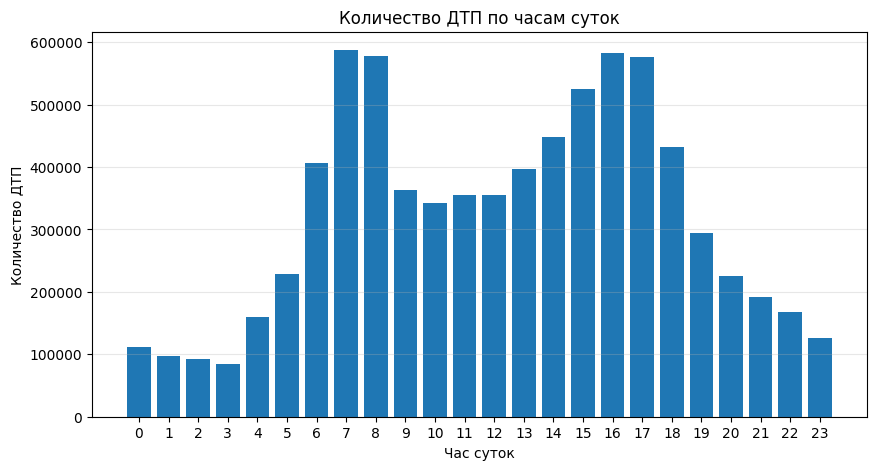

In [15]:

import matplotlib.pyplot as plt

hourly_pd = accidents_by_hour.toPandas()

plt.figure(figsize=(10, 5))
plt.bar(hourly_pd["hour"], hourly_pd["count"])

plt.title("Количество ДТП по часам суток")
plt.xlabel("Час суток")
plt.ylabel("Количество ДТП")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.show()


In [16]:

df_clean = df_prepared.filter(
    F.col("ID").isNotNull() &
    F.col("Severity").between(1, 4) &
    F.col("Start_Time").isNotNull() &
    F.col("End_Time").isNotNull() &
    (F.col("End_Time") >= F.col("Start_Time")) &
    F.col("Start_Lat").between(-90, 90) &
    F.col("Start_Lng").between(-180, 180) &
    (
        F.col("Humidity(%)").isNull() |
        F.col("Humidity(%)").between(0, 100)
    ) &
    (
        F.col("Visibility(mi)").isNull() |
        (F.col("Visibility(mi)") >= 0)
    ) &
    (
        F.col("Precipitation(in)").isNull() |
        (F.col("Precipitation(in)") >= 0)
    )
)

print("Исходных строк:", df.count())
print("Подготовленных строк:", df_clean.count())


Исходных строк: 7728394


Подготовленных строк: 7728394


In [17]:
numeric_columns = [
    "Temperature(F)",
    "Wind_Speed(mph)",
    "Visibility(mi)",
    "Precipitation(in)",
    "Distance(mi)"
]

df_typed.select(
    *[
        F.expr(f"`{c}`").alias(c)
        for c in numeric_columns
    ]
).summary("min", "25%", "50%", "75%", "max").show(truncate=False)

+-------+--------------+---------------+--------------+-----------------+------------+
|summary|Temperature(F)|Wind_Speed(mph)|Visibility(mi)|Precipitation(in)|Distance(mi)|
+-------+--------------+---------------+--------------+-----------------+------------+
|min    |-89.0         |0.0            |0.0           |0.0              |0.0         |
|25%    |49.0          |4.6            |10.0          |0.0              |0.0         |
|50%    |64.0          |7.0            |10.0          |0.0              |0.03        |
|75%    |76.0          |10.4           |10.0          |0.0              |0.464       |
|max    |207.0         |1087.0         |140.0         |36.47            |441.75      |
+-------+--------------+---------------+--------------+-----------------+------------+



In [18]:

from pyspark.sql import functions as F

outlier_conditions = {
    "Temperature(F)": (
        (F.col("Temperature(F)") < -40) |
        (F.col("Temperature(F)") > 130)
    ),
    "Wind_Speed(mph)": F.col("Wind_Speed(mph)") > 150,
    "Visibility(mi)": F.col("Visibility(mi)") > 30,
    "Precipitation(in)": F.col("Precipitation(in)") > 20,
    "Distance(mi)": F.col("Distance(mi)") > 50
}

outliers = df_typed.agg(
    *[
        F.sum(
            F.when(condition, 1).otherwise(0)
        ).alias(column)
        for column, condition in outlier_conditions.items()
    ]
)

display(outliers.toPandas().T.rename(columns={0: "Outliers"}))


,Outliers
Temperature(F),69
Wind_Speed(mph),51
Visibility(mi),5937
Precipitation(in),7
Distance(mi),715


In [19]:

# Экстремальные температуры
display(
    df_typed
    .filter(
        (F.col("Temperature(F)") < -40) |
        (F.col("Temperature(F)") > 130)
    )
    .select("ID", "State", "Start_Time",
            "Temperature(F)", "Weather_Condition")
    .orderBy(F.desc("Temperature(F)"))
    .limit(10)
    .toPandas()
)

# Экстремальная скорость ветра
display(
    df_typed
    .filter(F.col("Wind_Speed(mph)") > 150)
    .select("ID", "State", "Start_Time",
            "Wind_Speed(mph)", "Weather_Condition")
    .orderBy(F.desc("Wind_Speed(mph)"))
    .limit(10)
    .toPandas()
)


,ID,State,Start_Time,Temperature(F),Weather_Condition
0,A-4239885,CA,2023-02-22 19:24:00,207.0,Cloudy
1,A-5067455,CA,2023-02-22 19:30:00,207.0,Cloudy
2,A-4580836,CA,2023-02-22 20:10:00,207.0,Cloudy
3,A-1390354,TX,2020-07-17 11:41:59,203.0,Fair
4,A-5892168,AL,2021-08-12 13:03:26,196.0,Fair
5,A-5642539,AL,2021-08-12 13:03:26,196.0,Fair
6,A-6056189,AL,2021-08-12 13:03:26,196.0,Fair
7,A-938653,AL,2021-08-12 14:11:52,196.0,Fair
8,A-938722,AL,2021-08-12 13:05:36,196.0,Fair
9,A-1288293,OH,2020-09-07 10:31:21,189.0,T-Storm


,ID,State,Start_Time,Wind_Speed(mph),Weather_Condition
0,A-6320814,CA,2021-12-16 12:31:00,1087.0,Cloudy / Windy
1,A-7142243,FL,2020-03-28 14:49:27,984.0,Fair / Windy
2,A-114587,CA,2016-06-13 18:28:43,822.8,Clear
3,A-3424427,CA,2016-06-13 15:58:19,822.8,Clear
4,A-114595,CA,2016-06-13 18:44:57,822.8,Clear
5,A-3424437,CA,2016-06-13 17:11:24,822.8,Clear
6,A-114640,CA,2016-06-13 20:06:45,822.8,Clear
7,A-114647,CA,2016-06-13 20:19:08,822.8,Clear
8,A-114654,CA,2016-06-13 20:30:47,822.8,Clear
9,A-5785251,TX,2021-07-12 17:44:46,812.0,Fair / Windy


### Обработка выбросов

При анализе числовых признаков обнаружены аномальные значения температуры (до 207 °F) и скорости ветра (до 1087 mph).

Для очистки установлены пороговые значения: 140 °F для температуры и 200 mph для скорости ветра. Превышающие их значения заменяются на `null`.

При этом сами записи о ДТП сохраняются, чтобы избежать потери полезной информации. Остальные потенциальные выбросы пока оставлены без изменений.

In [20]:

from pyspark.sql import functions as F

df_clean = (
    df_clean
    .withColumn(
        "Temperature(F)",
        F.when(
            F.col("Temperature(F)") > 140,
            None
        ).otherwise(F.col("Temperature(F)"))
    )
    .withColumn(
        "Wind_Speed(mph)",
        F.when(
            F.col("Wind_Speed(mph)") > 200,
            None
        ).otherwise(F.col("Wind_Speed(mph)"))
    )
)


In [21]:
df_clean.select(
    "Temperature(F)",
    "Wind_Speed(mph)"
).summary("min", "max").show()

+-------+--------------+---------------+
|summary|Temperature(F)|Wind_Speed(mph)|
+-------+--------------+---------------+
|    min|         -89.0|            0.0|
|    max|         140.0|          190.0|
+-------+--------------+---------------+



In [22]:
display(
    df_clean
    .filter(F.col("Temperature(F)").isNotNull())
    .select(
        "ID", "State", "Start_Time",
        "Temperature(F)", "Weather_Condition"
    )
    .orderBy(F.asc("Temperature(F)"))
    .limit(15)
    .toPandas()
)

,ID,State,Start_Time,Temperature(F),Weather_Condition
0,A-1545585,CO,2020-04-03 08:15:53,-89.0,Cloudy
1,A-7153842,CO,2020-04-03 07:23:13,-89.0,Cloudy
2,A-1545574,CO,2020-04-03 07:37:17,-89.0,Cloudy
3,A-7153848,CO,2020-04-03 07:56:58,-89.0,Cloudy
4,A-1545576,CO,2020-04-03 07:44:19,-89.0,Cloudy
5,A-1545578,CO,2020-04-03 07:50:12,-89.0,Cloudy
6,A-1545580,CO,2020-04-03 07:58:54,-89.0,Cloudy
7,A-1545581,CO,2020-04-03 07:59:49,-89.0,Cloudy
8,A-1545583,CO,2020-04-03 08:05:15,-89.0,Cloudy
9,A-1545584,CO,2020-04-03 08:10:07,-89.0,Cloudy


### Итоговая обработка выбросов

После дополнительного анализа аномальных значений были уточнены правила очистки:

- Температура вне диапазона от −70 до 135 °F заменяется на `null`.
- Скорость ветра выше 150 mph заменяется на `null`.
- Остальные потенциальные выбросы сохраняются без изменений.

Очистка повторно применяется к исходному подготовленному датафрейму `df_prepared`. Строки с ДТП не удаляются.

In [23]:
# Считаем оставшиеся аномалии
bad_temp = df_clean.filter(
    (F.col("Temperature(F)") < -70) |
    (F.col("Temperature(F)") > 135)
).count()

print("Дополнительных аномальных значений:", bad_temp)

# Заменяем аномальные температуры на null
df_clean = df_clean.withColumn(
    "Temperature(F)",
    F.when(
        (F.col("Temperature(F)") < -70) |
        (F.col("Temperature(F)") > 135),
        F.lit(None).cast("double")
    ).otherwise(F.col("Temperature(F)"))
)

# Проверяем результат
df_clean.select("Temperature(F)").summary("min", "max").show()

Дополнительных аномальных значений: 41


+-------+--------------+
|summary|Temperature(F)|
+-------+--------------+
|    min|         -58.0|
|    max|         132.8|
+-------+--------------+



In [24]:

# Признаки и предварительные пороги выбросов
outlier_limits = {
    "Wind_Speed(mph)": 150,
    "Visibility(mi)": 30,
    "Precipitation(in)": 20,
    "Distance(mi)": 50
}

# Смотрим 10 максимальных значений каждого признака
for column, threshold in outlier_limits.items():
    print(f"\n{column} — значения выше {threshold}")

    result = (
        df_clean
        .filter(F.col(column) > threshold)
        .select("ID", "State", "Start_Time", column)
        .orderBy(F.desc(column))
        .limit(10)
    )

    display(result.toPandas())



Wind_Speed(mph) — значения выше 150


,ID,State,Start_Time,Wind_Speed(mph)
0,A-3782868,CA,2022-08-08 16:06:30,190.0
1,A-688030,OH,2022-03-05 11:07:51,188.0
2,A-5392267,FL,2022-06-26 15:06:00,185.0
3,A-4217581,FL,2022-06-26 14:50:00,185.0
4,A-2169846,NY,2019-04-16 10:53:14,175.0
5,A-2169848,NY,2019-04-16 11:00:47,175.0
6,A-2169852,NY,2019-04-16 11:44:58,175.0
7,A-3648096,CA,2017-07-10 17:11:32,174.9
8,A-491524,CA,2017-07-10 16:56:50,174.9
9,A-7320443,NJ,2019-12-19 14:51:31,169.0



Visibility(mi) — значения выше 30


,ID,State,Start_Time,Visibility(mi)
0,A-3082453,CA,2018-01-23 07:42:34,140.0
1,A-7636973,CA,2018-01-23 08:02:29,140.0
2,A-5680930,CA,2021-05-15 20:41:00,140.0
3,A-7366026,NH,2019-11-02 02:22:30,130.0
4,A-6656784,NH,2020-10-30 23:41:44,120.0
5,A-6793898,NH,2020-10-31 00:16:09,120.0
6,A-6721025,NH,2020-10-31 00:16:09,120.0
7,A-6805070,NH,2020-10-31 00:16:09,120.0
8,A-6764609,NH,2020-10-31 00:16:09,120.0
9,A-3442215,TX,2016-06-27 12:40:48,111.0



Precipitation(in) — значения выше 20


,ID,State,Start_Time,Precipitation(in)
0,A-597351,TN,2022-06-10 05:46:26,36.47
1,A-1879782,TN,2019-09-25 05:59:53,25.00
2,A-7340730,CA,2019-10-14 12:24:00,24.00
3,A-6788881,AL,2020-12-06 18:22:00,24.00
4,A-6494502,OK,2021-02-14 22:30:30,24.00
5,A-6891826,AL,2020-12-06 18:22:00,24.00
6,A-769716,VA,2021-12-21 21:55:25,23.97



Distance(mi) — значения выше 50


,ID,State,Start_Time,Distance(mi)
0,A-1275668,NV,2020-11-09 07:48:27,441.750000
1,A-575357,LA,2022-07-05 09:26:35,336.570007
2,A-2640497,SC,2018-08-11 12:44:43,333.630005
3,A-3132746,CO,2017-12-15 17:48:07,254.399994
4,A-1550775,NV,2020-04-09 07:18:40,251.220001
5,A-1028310,MO,2021-05-27 13:01:49,242.339996
6,A-3251244,CA,2017-10-17 09:03:08,227.210007
7,A-2925511,IA,2018-03-04 17:24:10,224.589996
8,A-974568,PA,2021-07-08 21:24:29,210.080002
9,A-561309,TX,2022-07-20 04:08:45,194.729996


In [25]:

import pandas as pd

numeric_cols = [
    "Temperature(F)",
    "Wind_Speed(mph)",
    "Visibility(mi)",
    "Precipitation(in)",
    "Distance(mi)"
]

probabilities = [0.01, 0.25, 0.50, 0.75, 0.99, 0.999]

quantiles = df_typed.approxQuantile(
    numeric_cols,
    probabilities,
    0.0005
)

quantiles_df = pd.DataFrame(
    quantiles,
    index=numeric_cols,
    columns=["P1", "P25", "P50", "P75", "P99", "P99.9"]
)

display(quantiles_df.round(3))


,P1,P25,P50,P75,P99,P99.9
Temperature(F),12.2,49.0,64.00,76.000,96.000,105.80
Wind_Speed(mph),0.0,4.6,7.00,10.400,23.000,31.00
Visibility(mi),0.5,10.0,10.00,10.000,10.000,30.00
Precipitation(in),0.0,0.0,0.00,0.000,0.180,0.65
Distance(mi),0.0,0.0,0.03,0.464,6.908,18.57


In [26]:

from pyspark.sql import functions as F

df_clean = (
    df_prepared
    .withColumn(
        "Temperature(F)",
        F.when(
            F.col("Temperature(F)").between(-70, 135),
            F.col("Temperature(F)")
        ).otherwise(None)
    )
    .withColumn(
        "Wind_Speed(mph)",
        F.when(
            (F.col("Wind_Speed(mph)") <= 150),
            F.col("Wind_Speed(mph)")
        ).otherwise(None)
    )
)

# Проверяем результат
print("Количество строк:", df_clean.count())

df_clean.select(
    "Temperature(F)",
    "Wind_Speed(mph)"
).summary("min", "max").show()


Количество строк: 7728394


+-------+--------------+---------------+
|summary|Temperature(F)|Wind_Speed(mph)|
+-------+--------------+---------------+
|    min|         -58.0|            0.0|
|    max|         132.8|          145.0|
+-------+--------------+---------------+



In [ ]:
output_path = "hdfs://namenode:8020/data/curated/accidents/"

(
    df_clean.write
    .mode("ignore")
    .partitionBy("year")
    .parquet(output_path)
)

print("Запись завершена или существующие данные сохранены")

Данные успешно сохранены!


In [28]:
df_parquet = spark.read.parquet(output_path)

print("Количество строк:", df_parquet.count())
print("Количество столбцов:", len(df_parquet.columns))

display(df_parquet.limit(5).toPandas())

Количество строк: 7728394
Количество столбцов: 51


,ID,Source,Severity,Start_Time,End_Time,Start_Lat,Start_Lng,End_Lat,End_Lng,Distance(mi),...,Turning_Loop,Sunrise_Sunset,Civil_Twilight,Nautical_Twilight,Astronomical_Twilight,month,hour,day_of_week,is_weekend,year
0,A-5815622,Source1,2,2021-09-02 13:55:34,2021-09-02 17:17:13,34.143692,-81.233203,34.136468,-81.217236,1.041,...,False,Day,Day,Day,Day,9,13,5,False,2021
1,A-5514705,Source1,2,2021-06-24 20:01:00,2021-06-24 22:03:05,32.797632,-117.241138,32.798846,-117.240575,0.090,...,False,Night,Day,Day,Day,6,20,5,False,2021
2,A-5815623,Source1,2,2021-08-18 10:00:28,2021-08-18 12:06:22,32.304906,-95.278830,32.304904,-95.278277,0.032,...,False,Day,Day,Day,Day,8,10,4,False,2021
3,A-5514706,Source1,2,2021-04-15 04:37:00,2021-04-15 20:13:06,38.631171,-77.418675,38.636699,-77.432112,0.820,...,False,Night,Night,Night,Night,4,4,5,False,2021
4,A-5815624,Source1,2,2021-12-24 09:11:16,2021-12-24 11:17:39,40.737745,-74.366037,40.736755,-74.361597,0.242,...,False,Day,Day,Day,Day,12,9,6,False,2021


# 2. Примените методы интеллектуального анализа данных 
кластеризация K-Means

Для кластеризации использована случайная выборка 2% данных. Пропущенные значения заполнены медианой, а признаки стандартизированы. Количество кластеров выбрано путём сравнения Silhouette Score.

In [29]:

features = [
    "Temperature(F)",
    "Humidity(%)",
    "Visibility(mi)",
    "Wind_Speed(mph)"
]

df_cluster = (
    df_parquet
    .select(*features)
    .sample(
        withReplacement=False,
        fraction=0.02,
        seed=42
    )
)

print("Количество записей:", df_cluster.count())

display(df_cluster.limit(10).toPandas())


Количество записей: 155064


,Temperature(F),Humidity(%),Visibility(mi),Wind_Speed(mph)
0,89.0,55.0,10.0,12.0
1,70.0,51.0,10.0,6.0
2,73.0,22.0,10.0,7.0
3,84.0,40.0,10.0,6.0
4,NaN,NaN,10.0,6.0
5,36.0,67.0,10.0,0.0
6,85.0,55.0,10.0,0.0
7,86.0,67.0,10.0,9.0
8,70.0,87.0,6.0,10.0
9,80.0,34.0,10.0,5.0


In [30]:

from pyspark.ml.feature import Imputer

features = [
    "Temperature(F)",
    "Humidity(%)",
    "Visibility(mi)",
    "Wind_Speed(mph)"
]

# Выборка 2% с дополнительными столбцами для анализа
df_cluster = (
    df_parquet
    .select("ID", "Severity", "State", "hour", *features)
    .sample(False, 0.02, seed=42)
)

# Новые столбцы с заполненными пропусками
filled_cols = [c + "_filled" for c in features]

imputer = Imputer(
    inputCols=features,
    outputCols=filled_cols,
    strategy="median"
)

df_cluster_filled = imputer.fit(df_cluster).transform(df_cluster)

display(
    df_cluster_filled
    .select("ID", *filled_cols)
    .limit(10)
    .toPandas()
)


,ID,Temperature(F)_filled,Humidity(%)_filled,Visibility(mi)_filled,Wind_Speed(mph)_filled
0,A-5815630,89.0,55.0,10.0,12.0
1,A-5514757,70.0,51.0,10.0,6.0
2,A-5514759,73.0,22.0,10.0,7.0
3,A-5514797,84.0,40.0,10.0,6.0
4,A-5514805,64.0,67.0,10.0,6.0
5,A-5815740,36.0,67.0,10.0,0.0
6,A-5514832,85.0,55.0,10.0,0.0
7,A-5514862,86.0,67.0,10.0,9.0
8,A-5815788,70.0,87.0,6.0,10.0
9,A-5514904,80.0,34.0,10.0,5.0


### Стандартизация

In [35]:

from pyspark.ml.feature import VectorAssembler, StandardScaler

# Объединяем признаки в один вектор
assembler = VectorAssembler(
    inputCols=filled_cols,
    outputCol="features_raw"
)

df_vector = assembler.transform(df_cluster_filled)

# Стандартизируем признаки
scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features_scaled",
    withMean=True,
    withStd=True
)

scaler_model = scaler.fit(df_vector)
df_scaled = scaler_model.transform(df_vector)

# Проверяем результат
display(
    df_scaled.select(
        "ID",
        "features_raw",
        "features_scaled"
    ).limit(5).toPandas()
)


,ID,features_raw,features_scaled
0,A-5815630,"[89.0, 55.0, 10.0, 12.0]","[1.453374133951812, -0.4353879448277934, 0.328..."
1,A-5514757,"[70.0, 51.0, 10.0, 6.0]","[0.43948555197377576, -0.6126855985855877, 0.3..."
2,A-5514759,"[73.0, 22.0, 10.0, 7.0]","[0.5995732228124131, -1.8980935883295962, 0.32..."
3,A-5514797,"[84.0, 40.0, 10.0, 6.0]","[1.1865613492207499, -1.100254146419522, 0.328..."
4,A-5514805,"[64.0, 67.0, 10.0, 6.0]","[0.11931021029650116, 0.09650501644558938, 0.3..."


In [36]:

from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.ml.clustering import KMeans

kmeans = KMeans(
    featuresCol="features_scaled",
    predictionCol="cluster",
    k=3,
    seed=42,
    maxIter=20
)

# Обучаем модель
kmeans_model = kmeans.fit(df_scaled)

# Присваиваем каждой записи номер кластера
df_clusters = kmeans_model.transform(df_scaled)

# Смотрим количество ДТП в каждом кластере
cluster_counts = (
    df_clusters
    .groupBy("cluster")
    .count()
    .orderBy("cluster")
)

display(cluster_counts.toPandas())


evaluator = ClusteringEvaluator(
    featuresCol="features_scaled",
    predictionCol="cluster",
    metricName="silhouette",
    distanceMeasure="squaredEuclidean"
)

silhouette = evaluator.evaluate(df_clusters)

print("Silhouette Score:", round(silhouette, 4))


,cluster,count
0,0,17471
1,1,74362
2,2,63231


Silhouette Score: 0.4076


In [37]:

results = [{"k": 3, "Silhouette": silhouette}]

for k in [2, 4, 5]:
    model = KMeans(
        featuresCol="features_scaled",
        predictionCol="cluster",
        k=k,
        seed=42,
        maxIter=20
    ).fit(df_scaled)

    predictions = model.transform(df_scaled)

    score = evaluator.evaluate(predictions)

    results.append({
        "k": k,
        "Silhouette": score
    })

scores_df = pd.DataFrame(results).sort_values("k")

display(scores_df)


,k,Silhouette
1,2,0.387384
0,3,0.407592
2,4,0.413015
3,5,0.378812


Выбираем k=4 — среди проверенных вариантов оно даёт наибольший Silhouette Score.

In [38]:

from pyspark.ml.clustering import KMeans
from pyspark.sql import functions as F

# Обучаем итоговую модель с k=4
kmeans_final = KMeans(
    featuresCol="features_scaled",
    predictionCol="cluster",
    k=4,
    seed=42,
    maxIter=20
)

model_final = kmeans_final.fit(df_scaled)
df_clusters_final = model_final.transform(df_scaled)

# Считаем характеристики каждого кластера
cluster_summary = (
    df_clusters_final
    .groupBy("cluster")
    .agg(
        F.count("*").alias("count"),
        F.round(F.avg("Temperature(F)_filled"), 1).alias("temperature"),
        F.round(F.avg("Humidity(%)_filled"), 1).alias("humidity"),
        F.round(F.avg("Visibility(mi)_filled"), 1).alias("visibility"),
        F.round(F.avg("Wind_Speed(mph)_filled"), 1).alias("wind_speed")
    )
    .orderBy("cluster")
)

display(cluster_summary.toPandas())


,cluster,count,temperature,humidity,visibility,wind_speed
0,0,16673,48.1,90.6,3.0,7.5
1,1,47438,76.3,42.3,10.0,7.1
2,2,64896,55.6,76.9,9.7,5.0
3,3,26057,59.4,59.4,9.9,15.2


K-Means выявил четыре группы(Низкая видимость, Тёплая сухая, Прохладная влажная, Ветреная) погодных условий, при которых регистрировались ДТП. Наибольшую группу составляют происшествия в прохладную влажную погоду.

In [39]:

from pyspark.sql import functions as F

cluster_severity = (
    df_clusters_final
    .groupBy("cluster")
    .agg(
        F.count("*").alias("count"),
        *[
            F.round(
                F.avg(
                    F.when(F.col("Severity") == s, 1.0)
                     .otherwise(0.0)
                ) * 100,
                2
            ).alias(f"Severity_{s}_pct")
            for s in range(1, 5)
        ]
    )
    .orderBy("cluster")
)

display(cluster_severity.toPandas())


,cluster,count,Severity_1_pct,Severity_2_pct,Severity_3_pct,Severity_4_pct
0,0,16673,0.45,78.83,17.93,2.79
1,1,47438,0.97,80.55,16.37,2.12
2,2,64896,0.87,80.07,16.14,2.92
3,3,26057,0.61,78.68,18.13,2.58


### Результаты кластеризации K-Means

Для интеллектуального анализа данных применён алгоритм K-Means на выборке из 155 064 ДТП. Признаки были заполнены медианными значениями и стандартизированы.

По результатам сравнения моделей выбрано 4 кластера (Silhouette Score = 0,413). Выделены группы с низкой видимостью, тёплой сухой погодой, прохладной влажной погодой и повышенной скоростью ветра.

Анализ показал, что доля происшествий с Severity 3–4 выше в кластерах с низкой видимостью (20,72%) и повышенной скоростью ветра (20,71%), чем в кластере с тёплой сухой погодой (18,49%).

Полученные различия носят описательный характер и требуют дальнейшей статистической проверки.

# 3. Обучение ML моделей

In [41]:
from pyspark.ml.classification import LogisticRegression
import numpy as np

# Создаем бинарную целевую переменную
df_regression = df_scaled.withColumn(
    "high_severity",
    F.when(F.col("Severity") >= 3, 1.0).otherwise(0.0)
)

# Обучаем логистическую регрессию
lr = LogisticRegression(
    featuresCol="features_scaled",
    labelCol="high_severity",
    maxIter=50,
    regParam=0.0
)

lr_model = lr.fit(df_regression)

# Коэффициенты и отношения шансов
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": lr_model.coefficients.toArray(),
    "Odds Ratio": np.exp(lr_model.coefficients.toArray())
})

display(coefficients.round(4))


,Feature,Coefficient,Odds Ratio
0,Temperature(F),0.0035,1.0035
1,Humidity(%),0.0832,1.0868
2,Visibility(mi),0.0264,1.0267
3,Wind_Speed(mph),0.1291,1.1378


### Регрессионный анализ

Для исследования связи погодных условий с тяжестью влияния ДТП на движение применена логистическая регрессия. Целевая переменная — принадлежность происшествия к категориям Severity 3–4.

Наиболее сильная положительная связь обнаружена для скорости ветра (OR = 1,138) и влажности (OR = 1,087). Температура показала практически нулевую связь (OR = 1,004).

Результаты отражают статистические ассоциации при учёте остальных признаков модели и не позволяют делать причинно-следственные выводы.

In [42]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, VectorAssembler
from pyspark.ml.classification import DecisionTreeClassifier
from pyspark.sql import functions as F

# Целевая переменная: Severity 1–4 -> label 0–3
df_ml = df_cluster.withColumn(
    "label",
    (F.col("Severity") - 1).cast("double")
)

# Делим выборку
train, test = df_ml.randomSplit([0.8, 0.2], seed=42)

# Заполнение пропусков медианой
imputer_ml = Imputer(
    inputCols=features,
    outputCols=filled_cols,
    strategy="median"
)

# Объединение признаков
assembler_ml = VectorAssembler(
    inputCols=filled_cols,
    outputCol="features"
)

# Дерево решений
tree = DecisionTreeClassifier(
    featuresCol="features",
    labelCol="label",
    maxDepth=5,
    seed=42
)

# Единый ML-пайплайн
pipeline = Pipeline(stages=[
    imputer_ml,
    assembler_ml,
    tree
])

# Обучение
model_tree = pipeline.fit(train)

# Предсказания на тестовой выборке
predictions = model_tree.transform(test)

display(
    predictions
    .select(
        "Severity",
        (F.col("prediction") + 1).alias("Predicted_Severity")
    )
    .limit(10)
    .toPandas()
)


,Severity,Predicted_Severity
0,2,2.0
1,2,2.0
2,2,2.0
3,2,2.0
4,2,2.0
5,2,2.0
6,2,2.0
7,2,2.0
8,2,2.0
9,2,2.0


In [43]:
pred_distribution = (
    predictions
    .groupBy("prediction")
    .count()
    .orderBy("prediction")
)

display(pred_distribution.toPandas())

,prediction,count
0,1.0,30833
1,2.0,6


In [44]:
# Матрица ошибок
cm_data = (
    predictions
    .groupBy("label", "prediction")
    .count()
    .toPandas()
)

cm = pd.pivot_table(
    cm_data,
    values="count",
    index="label",
    columns="prediction",
    fill_value=0
).reindex(
    index=[0.0, 1.0, 2.0, 3.0],
    columns=[0.0, 1.0, 2.0, 3.0],
    fill_value=0
)

cm.index = [1, 2, 3, 4]
cm.columns = [1, 2, 3, 4]

display(cm)

# Метрики
m = cm.to_numpy()
tp = np.diag(m)

precision = np.divide(
    tp, m.sum(axis=0),
    out=np.zeros(4, dtype=float),
    where=m.sum(axis=0) != 0
)

recall = np.divide(
    tp, m.sum(axis=1),
    out=np.zeros(4, dtype=float),
    where=m.sum(axis=1) != 0
)

f1 = np.divide(
    2 * precision * recall,
    precision + recall,
    out=np.zeros(4, dtype=float),
    where=(precision + recall) != 0
)

accuracy = tp.sum() / m.sum()
macro_f1 = f1.mean()

print("Accuracy:", round(accuracy, 4))
print("Macro-F1:", round(macro_f1, 4))
print("Baseline Accuracy:", round(m.sum(axis=1).max() / m.sum(), 4))

display(pd.DataFrame({
    "Severity": [1, 2, 3, 4],
    "Precision": precision,
    "Recall": recall,
    "F1": f1
}).round(3))


,1,2,3,4
1,0,251.0,0.0,0
2,0,24732.0,4.0,0
3,0,5040.0,1.0,0
4,0,810.0,1.0,0


Accuracy: 0.802
Macro-F1: 0.2226
Baseline Accuracy: 0.8021


,Severity,Precision,Recall,F1
0,1,0.000,0.0,0.00
1,2,0.802,1.0,0.89
2,3,0.167,0.0,0.00
3,4,0.000,0.0,0.00


In [45]:
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import Imputer, VectorAssembler
from pyspark.ml.classification import DecisionTreeClassifier

weather_features = [
    "Temperature(F)",
    "Humidity(%)",
    "Visibility(mi)",
    "Wind_Speed(mph)"
]

road_features = [
    "Traffic_Signal",
    "Crossing",
    "Junction",
    "Stop",
    "Railway"
]

time_features = ["hour", "month", "is_weekend"]

# Добавляем новые признаки
df_ml2 = (
    df_parquet
    .select(
        "Severity",
        *weather_features,
        *road_features,
        *time_features
    )
    .sample(False, 0.02, seed=42)
    .withColumn("label", (F.col("Severity") - 1).cast("double"))
)

# Преобразуем логические признаки в числа
for c in road_features + ["is_weekend"]:
    df_ml2 = df_ml2.withColumn(c, F.col(c).cast("double"))

# Делим данные на train и test
train2, test2 = df_ml2.randomSplit([0.8, 0.2], seed=42)

# Вычисляем веса классов на обучающей выборке
class_counts = train2.groupBy("label").count().collect()
total = sum(row["count"] for row in class_counts)
n_classes = len(class_counts)

class_weights = {
    row["label"]: total / (n_classes * row["count"])
    for row in class_counts
}

weight_expr = F.lit(1.0)

for label, weight in class_weights.items():
    weight_expr = F.when(
        F.col("label") == label, F.lit(weight)
    ).otherwise(weight_expr)

train2 = train2.withColumn("class_weight", weight_expr)

# Заполнение погодных пропусков
imputer2 = Imputer(
    inputCols=weather_features,
    outputCols=[c + "_filled" for c in weather_features],
    strategy="median"
)

# Подготовка признаков
assembler2 = VectorAssembler(
    inputCols=(
        [c + "_filled" for c in weather_features]
        + road_features + time_features
    ),
    outputCol="features_ml"
)

# Дерево с учетом весов классов
tree2 = DecisionTreeClassifier(
    featuresCol="features_ml",
    labelCol="label",
    weightCol="class_weight",
    maxDepth=8,
    minInstancesPerNode=50,
    seed=42
)

pipeline2 = Pipeline(stages=[
    imputer2,
    assembler2,
    tree2
])

model_tree2 = pipeline2.fit(train2)
predictions_improved = model_tree2.transform(test2)

display(
    predictions_improved
    .groupBy("prediction")
    .count()
    .orderBy("prediction")
    .toPandas()
)


,prediction,count
0,0.0,6261
1,1.0,4970
2,2.0,14161
3,3.0,5447


In [46]:
# Матрица ошибок
cm_data = (
    predictions_improved
    .groupBy("label", "prediction")
    .count()
    .toPandas()
)

cm = (
    cm_data.pivot(
        index="label",
        columns="prediction",
        values="count"
    )
    .reindex(index=[0., 1., 2., 3.],
             columns=[0., 1., 2., 3.],
             fill_value=0)
    .fillna(0)
)

cm.index = [1, 2, 3, 4]
cm.columns = [1, 2, 3, 4]

display(cm)

# Метрики качества
m = cm.to_numpy()
tp = np.diag(m)

precision = np.divide(
    tp, m.sum(axis=0),
    out=np.zeros(4, dtype=float),
    where=m.sum(axis=0) != 0
)

recall = np.divide(
    tp, m.sum(axis=1),
    out=np.zeros(4, dtype=float),
    where=m.sum(axis=1) != 0
)

f1 = np.divide(
    2 * precision * recall,
    precision + recall,
    out=np.zeros(4, dtype=float),
    where=(precision + recall) != 0
)

accuracy = tp.sum() / m.sum()
macro_f1 = f1.mean()
baseline = m.sum(axis=1).max() / m.sum()

print("Accuracy:", round(accuracy, 4))
print("Macro-F1:", round(macro_f1, 4))
print("Baseline Accuracy:", round(baseline, 4))

display(pd.DataFrame({
    "Severity": [1, 2, 3, 4],
    "Precision": precision,
    "Recall": recall,
    "F1": f1
}).round(3))


,1,2,3,4
1,173,9,57,6
2,4941,4564,10747,4320
3,996,309,2989,889
4,151,88,368,232


Accuracy: 0.258
Macro-F1: 0.1863
Baseline Accuracy: 0.7968


,Severity,Precision,Recall,F1
0,1,0.028,0.706,0.053
1,2,0.918,0.186,0.309
2,3,0.211,0.577,0.309
3,4,0.043,0.277,0.074


#### Cоздаём бинарную целевую переменную и разделяем выборку в пропорции 70/15/15 

In [47]:

weather_features = [
    "Temperature(F)",
    "Humidity(%)",
    "Visibility(mi)",
    "Wind_Speed(mph)",
    "Pressure(in)",
    "Precipitation(in)"
]

time_features = [
    "hour", "month", "day_of_week", "is_weekend"
]

road_features = [
    "Traffic_Signal", "Crossing", "Junction",
    "Stop", "Railway", "Station"
]

category_features = [
    "State", "Sunrise_Sunset", "Weather_Condition"
]

# Формируем выборку
df_binary = (
    df_parquet
    .select(
        "ID", "Severity",
        *weather_features,
        *time_features,
        *road_features,
        *category_features
    )
    .sample(False, 0.02, seed=42)
    .withColumn(
        "label",
        F.when(F.col("Severity") >= 3, 1.0).otherwise(0.0)
    )
)

# Boolean -> Double
for c in road_features + ["is_weekend"]:
    df_binary = df_binary.withColumn(
        c, F.col(c).cast("double")
    )

# Делим на train / validation / test
train, val, test = df_binary.randomSplit(
    [0.70, 0.15, 0.15], seed=42
)

print("Train:", train.count())
print("Validation:", val.count())
print("Test:", test.count())

display(
    df_binary.groupBy("label").count().orderBy("label").toPandas()
)


Train: 108841


Validation: 23140


Test: 23083


,label,count
0,0.0,125075
1,1.0,29989


In [48]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import (
    Imputer, StringIndexer,
    OneHotEncoder, VectorAssembler
)
from pyspark.ml.classification import RandomForestClassifier

# 1. Заполнение пропусков
imputer = Imputer(
    inputCols=weather_features,
    outputCols=[c + "_filled" for c in weather_features],
    strategy="median"
)

# 2. Кодирование категорий
indexers = [
    StringIndexer(
        inputCol=c,
        outputCol=c + "_idx",
        handleInvalid="keep"
    )
    for c in category_features
]

encoder = OneHotEncoder(
    inputCols=[c + "_idx" for c in category_features],
    outputCols=[c + "_vec" for c in category_features],
    handleInvalid="keep"
)

# 3. Объединение признаков
assembler = VectorAssembler(
    inputCols=(
        [c + "_filled" for c in weather_features]
        + time_features
        + road_features
        + [c + "_vec" for c in category_features]
    ),
    outputCol="features"
)

# 4. Random Forest
rf = RandomForestClassifier(
    featuresCol="features",
    labelCol="label",
    numTrees=20,
    maxDepth=6,
    minInstancesPerNode=50,
    seed=42
)

pipeline = Pipeline(
    stages=[imputer, *indexers, encoder, assembler, rf]
)

# Обучаем только на train
rf_model = pipeline.fit(train)

# Предсказываем на validation
pred_val = rf_model.transform(val)

display(
    pred_val.groupBy("prediction").count()
    .orderBy("prediction").toPandas()
)


,prediction,count
0,0.0,23140


In [49]:
from pyspark.ml.evaluation import BinaryClassificationEvaluator
import numpy as np
import pandas as pd

# Матрица ошибок
cm = (
    pred_val.groupBy("label", "prediction")
    .count().toPandas()
    .pivot(index="label", columns="prediction", values="count")
    .reindex(index=[0.0, 1.0], columns=[0.0, 1.0])
    .fillna(0).astype(int)
)

display(cm)

m = cm.to_numpy()
tp = np.diag(m)

precision = np.divide(
    tp, m.sum(axis=0),
    out=np.zeros(2, dtype=float),
    where=m.sum(axis=0) != 0
)

recall = np.divide(
    tp, m.sum(axis=1),
    out=np.zeros(2, dtype=float),
    where=m.sum(axis=1) != 0
)

f1 = np.divide(
    2 * precision * recall,
    precision + recall,
    out=np.zeros(2, dtype=float),
    where=precision + recall != 0
)

print("Accuracy:", round(tp.sum() / m.sum(), 4))
print("Macro-F1:", round(f1.mean(), 4))
print("Baseline Accuracy:", round(m.sum(axis=1).max() / m.sum(), 4))

display(pd.DataFrame({
    "Class": [0, 1],
    "Precision": precision,
    "Recall": recall,
    "F1": f1
}).round(4))

evaluator = BinaryClassificationEvaluator(labelCol="label")

print(
    "ROC-AUC:",
    round(evaluator.evaluate(
        pred_val, {evaluator.metricName: "areaUnderROC"}
    ), 4)
)

print(
    "PR-AUC:",
    round(evaluator.evaluate(
        pred_val, {evaluator.metricName: "areaUnderPR"}
    ), 4)
)


prediction,0.0,1.0
label,,
0.0,18688,0
1.0,4452,0


Accuracy: 0.8076
Macro-F1: 0.4468
Baseline Accuracy: 0.8076


,Class,Precision,Recall,F1
0,0,0.8076,1.0,0.8936
1,1,0.0000,0.0,0.0000


ROC-AUC: 0.7031


PR-AUC: 0.3619


In [51]:

from pyspark.ml.functions import vector_to_array
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, precision_score, recall_score

# Получаем вероятность класса 1
val_scores = (
    pred_val
    .select(
        "label",
        vector_to_array("probability")[1].alias("probability_1")
    )
    .toPandas()
)

y_true = val_scores["label"].to_numpy()
y_prob = val_scores["probability_1"].to_numpy()

results = []

# Проверяем разные пороги
for threshold in np.arange(0.05, 0.51, 0.025):
    y_pred = (y_prob >= threshold).astype(int)

    results.append({
        "Threshold": round(threshold, 3),
        "Macro-F1": f1_score(
            y_true, y_pred, average="macro"
        ),
        "Recall_1": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Precision_1": precision_score(
            y_true, y_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(results)

display(
    threshold_df
    .sort_values("Macro-F1", ascending=False)
    .head(10)
)


,Threshold,Macro-F1,Recall_1,Precision_1
7,0.225,0.613455,0.322776,0.407428
6,0.200,0.613022,0.567161,0.339610
8,0.250,0.574793,0.199236,0.419782
9,0.275,0.508433,0.070305,0.526936
5,0.175,0.474323,0.819407,0.249265
10,0.300,0.469576,0.023360,0.622754
11,0.325,0.458228,0.011456,0.653846
12,0.350,0.447461,0.000674,0.600000
15,0.425,0.446782,0.000000,0.000000
13,0.375,0.446782,0.000000,0.000000


In [52]:

from pyspark.ml.functions import vector_to_array
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)
import pandas as pd

# Лучший порог на валидационной выборке
best_threshold = 0.225

# Предсказания на тестовой выборке
pred_test = rf_model.transform(test)

test_scores = (
    pred_test
    .select(
        "label",
        vector_to_array("probability")[1].alias("probability_1")
    )
    .toPandas()
)

y_test = test_scores["label"].astype(int)
y_prob = test_scores["probability_1"]
y_pred = (y_prob >= best_threshold).astype(int)

# Метрики
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Macro-F1:", round(f1_score(y_test, y_pred, average="macro"), 4))
print("Precision (1):", round(precision_score(y_test, y_pred), 4))
print("Recall (1):", round(recall_score(y_test, y_pred), 4))
print("F1 (1):", round(f1_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("Average Precision:", round(average_precision_score(y_test, y_prob), 4))

# Матрица ошибок
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display(
    pd.DataFrame(
        cm,
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"]
    )
)


Accuracy: 0.7832
Macro-F1: 0.6135
Precision (1): 0.403
Recall (1): 0.3211
F1 (1): 0.3574
ROC-AUC: 0.7007
Average Precision: 0.3434


,Predicted 0,Predicted 1
Actual 0,16686,2062
Actual 1,2943,1392


#### Важность признаков

,Feature,Importance
72,Weather_Condition_vec_Clear,0.196363
69,Weather_Condition_vec_Fair,0.137162
11,Crossing,0.096728
10,Traffic_Signal,0.084055
76,Weather_Condition_vec_Scattered Clouds,0.070386
74,Weather_Condition_vec_Overcast,0.066198
26,State_vec_GA,0.054880
4,Pressure(in)_filled,0.030239
13,Stop,0.029106
20,State_vec_NY,0.026796


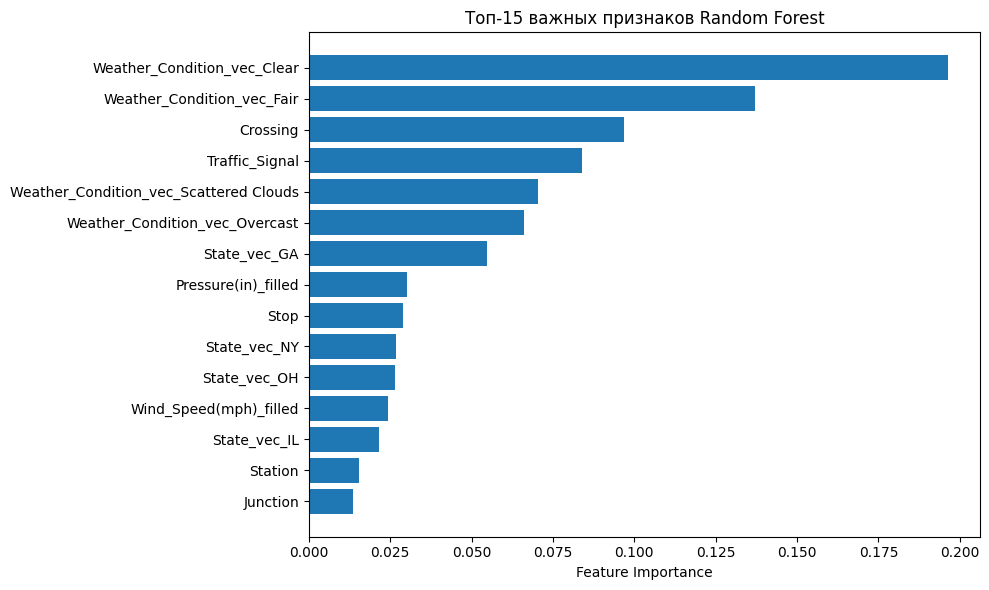

In [53]:

# Получаем обученный Random Forest из Pipeline
rf_stage = rf_model.stages[-1]

# Важность признаков
importances = rf_stage.featureImportances.toArray()

# Получаем имена признаков, включая One-Hot категории
metadata = pred_test.schema["features"].metadata
attrs = metadata.get("ml_attr", {}).get("attrs", {})

feature_names = {
    attr["idx"]: attr["name"]
    for group in attrs.values()
    for attr in group
}

importance_df = pd.DataFrame({
    "Feature": [
        feature_names.get(i, f"feature_{i}")
        for i in range(len(importances))
    ],
    "Importance": importances
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

display(importance_df.head(20))


top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Топ-15 важных признаков Random Forest")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()


### Итоги бинарной классификации Random Forest

Для прогнозирования степени влияния ДТП на движение обучена модель Random Forest с использованием 19 погодных, временных, географических и дорожных признаков.

Целевая переменная разделена на два класса: 0 — Severity 1–2, 1 — Severity 3–4. Данные разделены на обучающую (70%), валидационную (15%) и тестовую (15%) выборки.

**Результаты на тестовой выборке:**

- Accuracy — 0,7832
- Macro-F1 — 0,6135
- ROC-AUC — 0,7007
- Precision класса 1 — 0,4030
- Recall класса 1 — 0,3211

По результатам анализа важности признаков наибольший вклад в предсказания внесли погодные условия (`Weather_Condition`), наличие пешеходных переходов (`Crossing`), светофоров (`Traffic_Signal`) и географическое расположение (`State`).

**Вывод:** модель продемонстрировала умеренную способность различать классы ДТП (ROC-AUC ≈ 0,70), однако обнаруживает только 32,1% происшествий с Severity 3–4. Для учебного исследования результат позволяеат оценить возможности и ограничения прогнозирования на основе доступных признаков. Дальнейшее улучшение качества требует дополнительных экспериментов.


# 4. Проверка гипотез

Проверим три гипотезы:
1. H1: Распределение ДТП по часам суток различается между буднями и выходными.
2. H2: При низкой видимости доля ДТП с Severity 3–4 отличается от доли при хорошей видимости.
3. H3: Распределение Severity связано с погодными условиями.

### H1

,Weekday,Weekend
hour,,
0,1.16,2.99
1,0.98,2.70
2,0.91,2.79
3,0.86,2.29
4,2.04,2.23
5,3.08,2.28
6,5.72,2.79
7,8.43,3.24
8,8.25,3.37


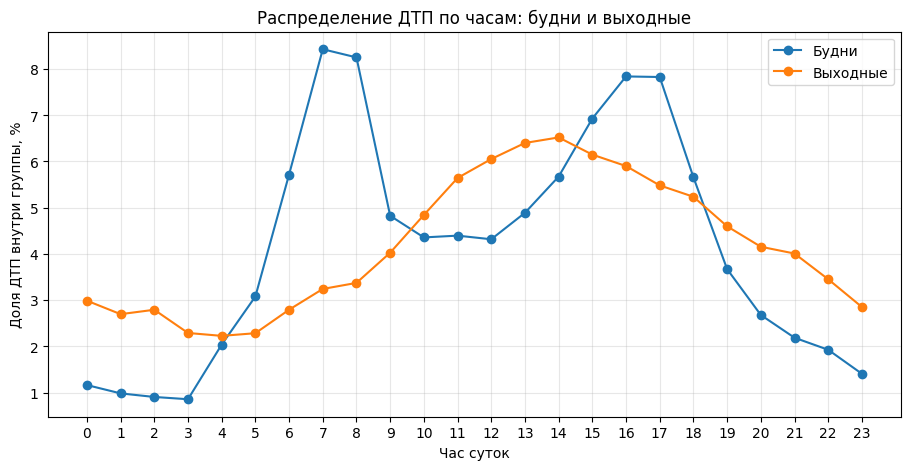

Chi-square: 267277.52
p-value: 0.0
Степени свободы: 23
Cramer's V: 0.186
H0 отвергается: распределения различаются


In [55]:

# Количество ДТП по часам и типу дня
hourly_data = (
    df_parquet
    .groupBy("is_weekend", "hour")
    .count()
    .toPandas()
)

# Формируем таблицу
hourly_table = (
    hourly_data
    .pivot(index="hour", columns="is_weekend", values="count")
    .reindex(index=range(24), columns=[False, True])
    .fillna(0)
)

hourly_table.columns = ["Weekday", "Weekend"]

# Переводим количество ДТП в проценты внутри каждой группы
hourly_pct = (
    hourly_table
    .div(hourly_table.sum(axis=0), axis=1)
    * 100
)

display(hourly_pct.round(2))


plt.figure(figsize=(11, 5))

plt.plot(
    hourly_pct.index,
    hourly_pct["Weekday"],
    marker="o",
    label="Будни"
)

plt.plot(
    hourly_pct.index,
    hourly_pct["Weekend"],
    marker="o",
    label="Выходные"
)

plt.title("Распределение ДТП по часам: будни и выходные")
plt.xlabel("Час суток")
plt.ylabel("Доля ДТП внутри группы, %")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)

plt.show()


import numpy as np
from scipy.stats import chi2_contingency

# Таблица абсолютных частот: 2 группы × 24 часа
observed = hourly_table.T.to_numpy()

# Критерий хи-квадрат
chi2, p_value, dof, expected = chi2_contingency(observed)

# Размер эффекта — V Крамера
n = observed.sum()
cramers_v = np.sqrt(
    chi2 / (n * min(observed.shape[0] - 1,
                    observed.shape[1] - 1))
)

print("Chi-square:", round(chi2, 2))
print("p-value:", p_value)
print("Степени свободы:", dof)
print("Cramer's V:", round(cramers_v, 4))

alpha = 0.05

if p_value < alpha:
    print("H0 отвергается: распределения различаются")
else:
    print("Нет оснований отвергнуть H0")


### Гипотеза 1. Зависимость распределения ДТП от времени суток и дня недели

**H₀:** Распределение ДТП по часам одинаково в будни и выходные.

**H₁:** Распределения различаются.

По результатам критерия χ² обнаружены статистически значимые различия (χ² = 267 277,52; p < 0,001; V Крамера = 0,186).

В будние дни наблюдаются выраженные пики в 7–8 и 16–17 часов, тогда как в выходные максимум приходится на 13–15 часов.

**Вывод:** нулевая гипотеза отвергается. Время суток и тип дня статистически связаны с распределением зарегистрированных ДТП. Сила связи относительно невелика.

### H2. Связь видимости и Severity

In [56]:

from pyspark.sql import functions as F

visibility_data = (
    df_parquet
    .filter(F.col("Visibility(mi)").isNotNull())
    .withColumn(
        "visibility_group",
        F.when(
            F.col("Visibility(mi)") <= 2, "Low"
        ).when(
            F.col("Visibility(mi)") >= 10, "Good"
        )
    )
    .filter(F.col("visibility_group").isNotNull())
    .withColumn(
        "high_severity",
        F.when(F.col("Severity") >= 3, 1).otherwise(0)
    )
)

visibility_summary = (
    visibility_data
    .groupBy("visibility_group")
    .agg(
        F.count("*").alias("total"),
        F.sum("high_severity").alias("high_severity_count")
    )
    .withColumn(
        "high_severity_pct",
        F.round(
            F.col("high_severity_count") / F.col("total") * 100,
            2
        )
    )
)

display(visibility_summary.toPandas())



,visibility_group,total,high_severity_count,high_severity_pct
0,Low,367880,69855,18.99
1,Good,6101076,1171080,19.19


,Severity 1-2,Severity 3-4
visibility_group,,
Low,298025,69855
Good,4929996,1171080


,Visibility,High Severity (%)
0,Low,18.989
1,Good,19.195



Результаты проверки:
Chi-square: 9.5081
p-value: 0.0020456928274465865
Cramer's V: 0.0012
Разница долей (п.п.): 0.206
H0 отвергается: доли статистически различаются


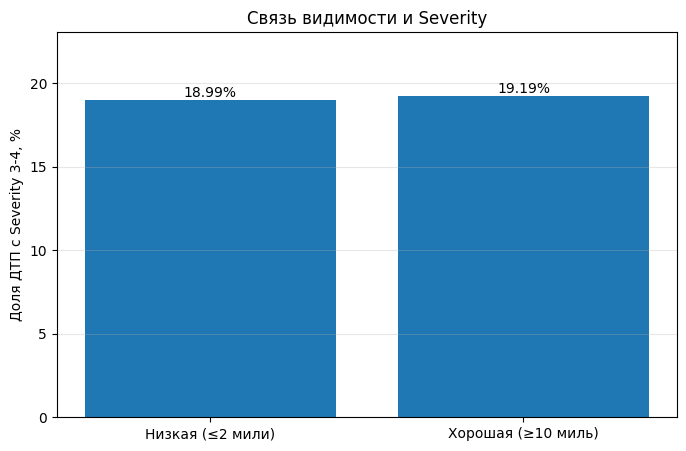

In [ ]:
from scipy.stats import chi2_contingency


# 1. Подготовка данных
visibility_data = (
    df_parquet
    .filter(F.col("Visibility(mi)").isNotNull())
    .withColumn(
        "visibility_group",
        F.when(F.col("Visibility(mi)") <= 2, "Low")
         .when(F.col("Visibility(mi)") >= 10, "Good")
    )
    .filter(F.col("visibility_group").isNotNull())
    .withColumn(
        "high_severity",
        F.when(F.col("Severity") >= 3, 1).otherwise(0)
    )
)

# 2. Агрегация в Spark
summary = (
    visibility_data
    .groupBy("visibility_group", "high_severity")
    .count()
    .toPandas()
)

# 3. Таблица сопряжённости
table = (
    summary.pivot(
        index="visibility_group",
        columns="high_severity",
        values="count"
    )
    .reindex(index=["Low", "Good"], columns=[0, 1])
    .fillna(0)
    .astype(int)
)

table.columns = ["Severity 1-2", "Severity 3-4"]

display(table)

# 4. Процент ДТП с высоким Severity
high_pct = (
    table["Severity 3-4"] / table.sum(axis=1) * 100
)

display(pd.DataFrame({
    "Visibility": high_pct.index,
    "High Severity (%)": high_pct.values
}).round(3))

# 5. Критерий хи-квадрат
chi2, p_value, dof, expected = chi2_contingency(
    table.to_numpy(),
    correction=False
)

# V Крамера
n = table.to_numpy().sum()
cramers_v = np.sqrt(chi2 / n)

# Разница долей (Good - Low)
difference = high_pct["Good"] - high_pct["Low"]

print("\nРезультаты проверки:")
print("Chi-square:", round(chi2, 4))
print("p-value:", p_value)
print("Cramer's V:", round(cramers_v, 4))
print("Разница долей (п.п.):", round(difference, 3))

if p_value < 0.05:
    print("H0 отвергается: доли статистически различаются")
else:
    print("Нет оснований отвергнуть H0")

# 6. График
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Низкая (≤2 мили)", "Хорошая (≥10 миль)"],
    high_pct.values
)

plt.ylabel("Доля ДТП с Severity 3-4, %")
plt.title("Связь видимости и Severity")
plt.ylim(0, max(high_pct.values) * 1.2)

for bar, value in zip(bars, high_pct.values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.2,
        f"{value:.2f}%",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.show()


### Гипотеза 2. Связь видимости и Severity

**H₀:** Доля ДТП с Severity 3–4 одинакова при низкой и хорошей видимости.

**H₁:** Доли различаются.

При уровне значимости α = 0,05 критерий χ² выявил статистически значимые различия (χ² = 9,51; p = 0,002; V Крамера = 0,0012).

Доля ДТП с Severity 3–4 при низкой видимости составила 18,99%, при хорошей — 19,19%. Разница составляет 0,206 процентного пункта.

**Вывод:** H₀ отвергается, однако обнаруженная связь крайне слабая и практически незначимая.

### Гипотеза 3. Связь погодных условий и Severity

Таблица абсолютных частот:


Severity,1,2,3,4
weather_group,,,,
Clear,337,536971,244956,26479
Cloudy,7985,692929,93340,22828
Fair,34359,2226576,240084,59783
Light Rain,2338,270162,71097,9360
Mostly Cloudy,10676,792735,189229,23555
Other,3709,572381,116661,19738
Overcast,115,248938,119946,13867
Partly Cloudy,6820,548760,127692,15700
Scattered Clouds,73,132748,66037,5971


Доля ДТП с высоким Severity:


,Total,Severity 3-4 (%)
weather_group,,
Scattered Clouds,204829,35.16
Overcast,382866,34.95
Clear,808743,33.56
Light Rain,352957,22.80
Mostly Cloudy,1016195,20.94
Partly Cloudy,698972,20.51
Other,712489,19.14
Cloudy,817082,14.22
Fair,2560802,11.71



Результаты проверки:
Chi-square: 346498.7083
p-value: 0.0
Степени свободы: 24
Cramer's V: 0.1236
Минимальная ожидаемая частота: 1800.56
H0 отвергается: погода и Severity статистически связаны


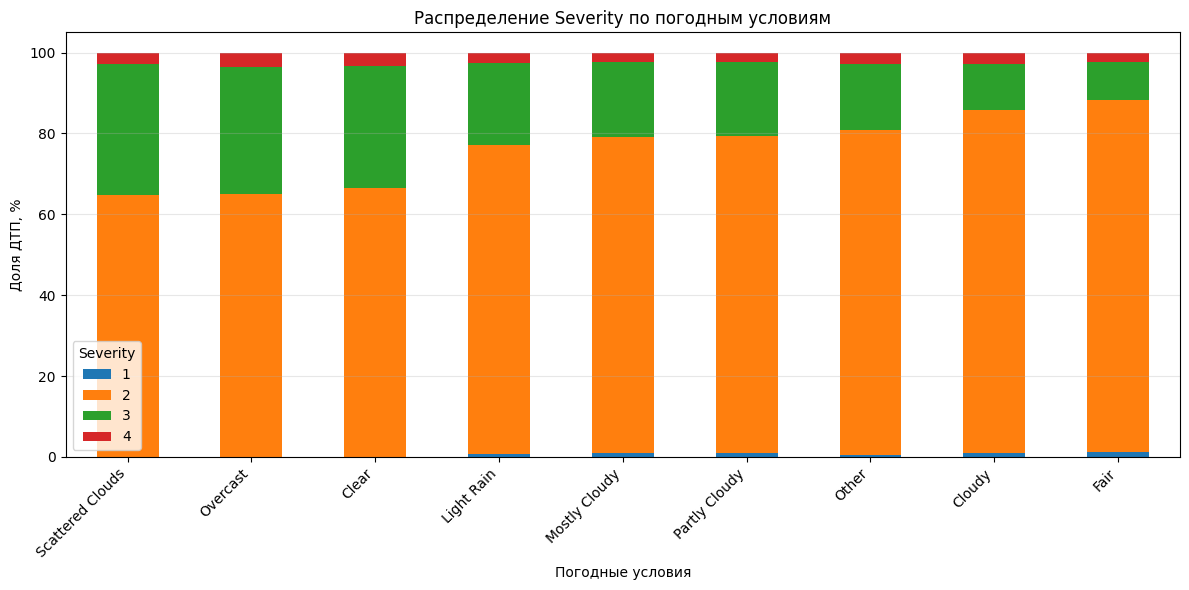

In [58]:

# 1. Убираем записи без информации о погоде
weather_data = (
    df_parquet
    .filter(
        F.col("Weather_Condition").isNotNull() &
        (F.trim(F.col("Weather_Condition")) != "")
    )
    .filter(F.col("Severity").between(1, 4))
)

# 2. Находим 8 самых распространенных категорий погоды
top_weather = [
    row["Weather_Condition"]
    for row in (
        weather_data
        .groupBy("Weather_Condition")
        .count()
        .orderBy(F.desc("count"))
        .limit(8)
        .collect()
    )
]

# Остальные категории объединяем в Other
weather_data = weather_data.withColumn(
    "weather_group",
    F.when(
        F.col("Weather_Condition").isin(top_weather),
        F.col("Weather_Condition")
    ).otherwise(F.lit("Other"))
)

# 3. Считаем количество ДТП по погоде и Severity
counts = (
    weather_data
    .groupBy("weather_group", "Severity")
    .count()
    .toPandas()
)

# 4. Таблица сопряженности
table = (
    counts.pivot_table(
        index="weather_group",
        columns="Severity",
        values="count",
        aggfunc="sum",
        fill_value=0
    )
    .reindex(columns=[1, 2, 3, 4], fill_value=0)
    .astype(int)
)

print("Таблица абсолютных частот:")
display(table)

# 5. Распределение Severity в процентах
weather_pct = (
    table.div(table.sum(axis=1), axis=0) * 100
)

summary = pd.DataFrame({
    "Total": table.sum(axis=1),
    "Severity 3-4 (%)": weather_pct[3] + weather_pct[4]
}).sort_values("Severity 3-4 (%)", ascending=False)

print("Доля ДТП с высоким Severity:")
display(summary.round(2))

# 6. Критерий хи-квадрат
chi2, p_value, dof, expected = chi2_contingency(
    table.to_numpy()
)

n = table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(table.shape[0] - 1,
                    table.shape[1] - 1))
)

alpha = 0.05

print("\nРезультаты проверки:")
print("Chi-square:", round(chi2, 4))
print("p-value:", p_value)
print("Степени свободы:", dof)
print("Cramer's V:", round(cramers_v, 4))
print("Минимальная ожидаемая частота:", round(expected.min(), 2))

if p_value < alpha:
    print("H0 отвергается: погода и Severity статистически связаны")
else:
    print("Нет оснований отвергнуть H0")

# 7. Визуализация
plot_data = weather_pct.loc[summary.index]

ax = plot_data.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Распределение Severity по погодным условиям")
plt.xlabel("Погодные условия")
plt.ylabel("Доля ДТП, %")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Severity")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Гипотеза 3. Зависимость Severity от погодных условий

**H₀:** Распределение Severity не зависит от погодных условий.

**H₁:** Между погодными условиями и Severity существует статистическая связь.

Для проверки применён критерий χ² независимости при уровне значимости α = 0,05.

**Результаты:** χ² = 346 498,71; p < 0,001; V Крамера = 0,1236.

Наибольшая доля ДТП с Severity 3–4 обнаружена при Scattered Clouds (35,16%), Overcast (34,95%) и Clear (33,56%), наименьшая — при Fair (11,71%).

**Вывод:** H₀ отвергается. Между категориями погодных условий и Severity обнаружена статистически значимая, но относительно слабая связь. Результаты могут зависеть от особенностей источников данных и не доказывают причинного влияния погоды.